## Instructions {-}

1. The check-in is a **live meeting with your team's mentor on Zoom**. You can do it **any time before the deadline: Mon, Nov 23 at 1:50 pm** (end of class). Mentors hold office hours on Zoom, and class time on Nov 23 (12:30–1:50 pm) is also open for check-ins. **Every team must finish by 1:50 pm on Nov 23.** Checking in early gives you more time to act on the feedback.

2. Fill in this notebook **before** your check-in. During the check-in, one team member shares their screen and walks the mentor through it. Run every cell first so the outputs are showing.

3. Keep it short. This is a progress snapshot, not a draft report. Bullet points are fine in the Markdown cells.

4. **Put the name of the person or people who did each part** in the *By ...* line under each heading.

5. The check-in is worth **4 points**, 1 point per section:

| Section | What the mentor looks for | Points |
|---|---|---|
| 1. Data loaded and cleaned | The data loads, and the main cleaning steps are done | 1 |
| 2. Early results | At least one real result or plot for each member's question | 1 |
| 3. What remains | A concrete plan, with names and target dates, to finish by your session | 1 |
| 4. Questions for the mentor | Specific questions or problems the team has thought about | 1 |

**Delete this Instructions section before your check-in.**

## Team overview

Fill in the table, one row per team member. The question should be the same one from your proposal, or the updated version if it changed.

| Team member | Question they will answer | Changed since the proposal? (Yes / No) |
|---|---|---|
| Yujin Tatar |Is there a correlation between Social Engagement Index and where Divvy trips and stations are concentrated?  |No |
| Anah Shaikh |Does the most prominent type of bike lane (protected, buffered, etc) in a community affect bike usage and which types of lanes have the most crashes? How does this data compare against the hardship index of each area? |No |
| Name 3 | | |
| Name 4 | | |

**Presentation session:** Session 1 (Wed, Nov 25) / Session 2 (Fri, Dec 11) *(keep one)*

**If any question changed since the proposal, explain why in one or two sentences:**

In [2]:
# Libraries used in this notebook. Add any others your team needs.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1) Data loaded and cleaned
*By \<Wiktoria Mleczko, Anah Shaikh, Yujin Tatar, Luke Hallum>*

Load your data and show that it is ready (or nearly ready) to analyze.

If you use more than one dataset, load each one and show how they are combined.

In [3]:
# Load the data. Use a relative path (for example, a "data" folder next to this notebook)
# so the notebook runs on any teammate's computer.
#Q1:
trip_path = "data/202609-divvy-tripdata.csv"
stations_path = "data/Divvy_Bicycle_Stations_20261117.csv"
sei_path = "data/Chicago Health Atlas.csv"
trip_data = pd.read_csv(trip_path)
stations = pd.read_csv(stations_path)
sei = pd.read_csv(sei_path)

# Size and first rows
print(trip_data.shape)
display(trip_data.head())
print(stations.shape)
display(stations.head())
print(sei.shape)
display(sei.head())

# ANAH

# bike routes (I will be looking at location and types of bike lanes)
bike_routes = pd.read_csv('data/Bike_Routes_20261123.csv')

# crashes
bike_crashes = pd.read_csv('data/Traffic_Crashes_-_Crashes_20261123.csv')

# community boundaries
communities = pd.read_csv('data/Boundaries_-_Community_Areas_20261123.csv')

# socioeconomic indicators
census = pd.read_csv('data/Census_Data_-_Selected_socioeconomic_indicators_in_Chicago,_2008_–_2012_20261123.csv')

FileNotFoundError: [Errno 2] No such file or directory: 'data/202609-divvy-tripdata.csv'

In [ ]:
# Column types and missing values
trip_data.info()
trip_data.isna().sum().sort_values(ascending=False)
stations.info()
stations.isna().sum().sort_values(ascending=False)
sei.info()
sei.isna().sum().sort_values(ascending=False)

<class 'pandas.DataFrame'>
RangeIndex: 770562 entries, 0 to 770561
Data columns (total 13 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   ride_id             770562 non-null  str    
 1   rideable_type       770562 non-null  str    
 2   started_at          770562 non-null  str    
 3   ended_at            770562 non-null  str    
 4   start_station_name  610221 non-null  str    
 5   start_station_id    610221 non-null  str    
 6   end_station_name    600529 non-null  str    
 7   end_station_id      600529 non-null  str    
 8   start_lat           770562 non-null  float64
 9   start_lng           770562 non-null  float64
 10  end_lat             769918 non-null  float64
 11  end_lng             769918 non-null  float64
 12  member_casual       770562 non-null  str    
dtypes: float64(4), str(9)
memory usage: 76.4 MB
<class 'pandas.DataFrame'>
RangeIndex: 1231 entries, 0 to 1230
Data columns (total 9 columns):
 #   C

Layer            1
Name             1
GEOID            1
Population       1
Longitude        1
Latitude         1
SGX_2020-2024    0
dtype: int64

In [ ]:
# Cleaning steps done so far. Add a comment above each step that says what it does and why.

# Drop unneccessary cols/rows
print(trip_data.shape, stations.shape, sei.shape)
trip_data = trip_data.drop(columns=["rideable_type", "started_at", "ended_at","start_station_name", "start_station_id", "end_station_name", "end_station_id", "member_casual"])
stations = stations.drop(columns=['Short Name'])
sei = sei.drop(columns=['Layer'])
sei = sei.drop(index=0)
print(trip_data.shape, stations.shape, sei.shape)

# Rename cols
sei = sei.rename(columns={"SGX_2020-2024": "SEI"})

# Convert a string to number
sei["SEI"] = pd.to_numeric(sei["SEI"], errors="coerce")

# ANAH
# dropping unneeded columns
bike_routes = bike_routes.drop(columns=['MI_CTRLINE', 'CONTRAFLOW'])
bike_crashes = bike_crashes.drop(columns=['CRASH_DATE_EST_I', "NOT_RIGHT_OF_WAY_I",'HIT_AND_RUN_I',"DAMAGE", 'INJURIES_FATAL', 'INJURIES_INCAPACITATING', "INJURIES_NON_INCAPACITATING",'INTERSECTION_RELATED_I','INJURIES_REPORTED_NOT_EVIDENT', "INJURIES_NO_INDICATION", "INJURIES_UNKNOWN", 'CRASH_DATE', 'POSTED_SPEED_LIMIT', 'TRAFFIC_CONTROL_DEVICE', 'DEVICE_CONDITION', 'WEATHER_CONDITION', 'LIGHTING_CONDITION', 'LANE_CNT', "ALIGNMENT","ROADWAY_SURFACE_COND","ROAD_DEFECT","REPORT_TYPE", "DATE_POLICE_NOTIFIED", 
                                          "BEAT_OF_OCCURRENCE","PHOTOS_TAKEN_I","STATEMENTS_TAKEN_I","DOORING_I","WORK_ZONE_I","WORK_ZONE_TYPE","WORKERS_PRESENT_I","NUM_UNITS","CRASH_MONTH", "CRASH_HOUR","CRASH_DAY_OF_WEEK","IDOT_CONTROL_NO"])

# taking out crashes that don't occur in the street where the bike lines are
bike_crashes[(bike_crashes['TRAFFICWAY_TYPE'] != 'ALLEY') & (bike_crashes['TRAFFICWAY_TYPE'] != 'PARKING LOT')]

# handling missing values

print(bike_routes.isna().sum())

print(bike_crashes.isna().sum())
# there is no way to fill in this information with the data provided, and it was only 33 out of 18,712 rows.
bike_crashes = bike_crashes.dropna(subset='LOCATION')

print(communities.isna().sum())

print(census.isna().sum())

# all significant missing values have been dealt with

# renaming columns to prepare for merge
bike_routes = bike_routes.rename(columns={'ST_NAME':'STREET_NAME'})

NameError: name 'trip_data' is not defined

**Cleaning summary.** In a few bullets:

- What you have cleaned so far (missing values, duplicates, data types, outliers, merges, new variables):

For Q1: cleaned by dropping unnecessary columns and rows, converted a column datatype, renamed a column to be easier to handle.

For Q3: I cleaned up bike route and crash information by dropping unecessary columns and dropping null values that could not be filled and renamed a column to handle merge. I saw no missing values in the community and census data except for one value in the community areas, but I found that insignificant so I kept it.

- What cleaning is still left:

Q1: There are 644 missing values in end coordinates in trip_data, but cannot be imputed, so that data should be handled carefully.

Q3: I need to drop uneccesary columns from the community and census data.

- Rows and columns before cleaning → after cleaning: 

Q1: trip data: (770562, 13), stations: (1231, 9), SEI: (78, 7) --> (770562, 5), (1231, 8), (77, 6)

## 2) Early results
Show **at least one** early result or plot **for each team member's question**. It does not need to be final or polished, but it should come from your real data.

Under each result, write one or two sentences on what it shows so far.

### Question 1: \<short version of the question\>
*By \<Name of team member\>*

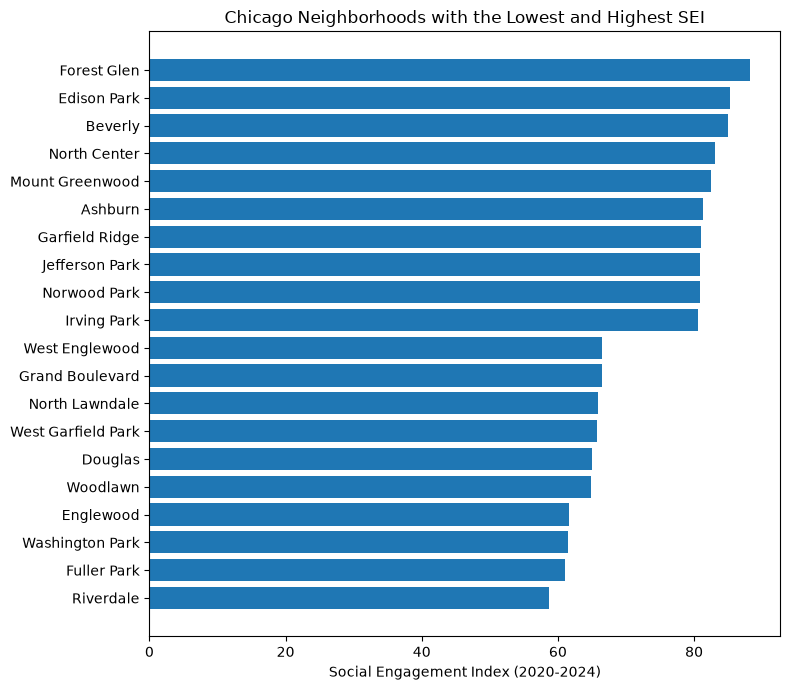

In [ ]:
# Early analysis or plot for question 1
# Seeing which neighborhoods have high and low SEI:

# Selecting the top 10 and bottom 10 SEI and combining them
top10 = sei.nlargest(10, "SEI")
bottom10 = sei.nsmallest(10, "SEI")
both = pd.concat([bottom10, top10]).sort_values("SEI")

# Making a horizontal bar plot since the neighborhood names are long, to represent the SEI visually
plt.figure(figsize=(8, 7))
plt.barh(both["Name"], both["SEI"])
plt.xlabel("Social Engagement Index (2020-2024)")
plt.title("Chicago Neighborhoods with the Lowest and Highest SEI")
plt.tight_layout()
plt.show()

**What this shows so far:**

The distribution of neighborhoods with high and low SEI. I will see if these neighborhoods are also the ones that have high/low concentration of trips and stations.

### Question 2: \<short version of the question\>
*By \<Name of team member\>*

In [ ]:
# Early analysis or plot for question 2
# Seeing how many crashes each bike lane type has over entire data timeline

**What this shows so far:**

### Question 3: \<short version of the question\>
*By Anah Shaikh*

In [4]:
# Early analysis or plot for question 3
# Seeing how many crashes each bike lane type has over entire data timeline

# Merging data by street name
bike_merged = bike_crashes.merge(bike_routes, on='STREET_NAME')

# Grouping Data
crash_counts = bike_merged.groupby('DISPLAYROU').size().reset_index(name='num_crashes')

# Visualizing Data
plt.figure(figsize=(12, 6))
sns.barplot(data=crash_counts, x='DISPLAYROU', y='num_crashes')
plt.xlabel('Type of Bike Lane')
plt.ylabel('Number of Crashes')
plt.title('Crashes per Type of Bike Lane')
plt.show()

NameError: name 'bike_crashes' is not defined

**What this shows so far:**
This shows that the Buffered Bike Lane has the most amount of crashes, with the Neighborhood Greenway trailing a decent way behind. The next step would be to determine if there's a pattern or trend, perhaps looking at if the amount of crashes increases with the amount of usage on certain bike routes.

### Question 4: \<short version of the question\>
*By \<Name of team member\>*

In [ ]:
# Early analysis or plot for question 4

**What this shows so far:**

## 3) What remains
List what is left to finish before your presentation and report. Give each item an owner and a target date.

| Task | Owner | Target date |
|---|---|---|
|Finish analyzing where the trips and stations are and then see the correlation with SEI|Yujin |11/24 |
|Finish analyzing possible correlation between bike lane type and crashes, then see how that data maps onto socio economic factors|Anah | |
| | | |

**Biggest risk to finishing on time** (one sentence):

## 4) Questions for the mentor
List the specific questions or problems you want help with. "Is this okay?" is too general. Say what you tried and what you are unsure about.

For example: *"Our income column is very right-skewed. Should we use a log scale in the plot or report medians instead of means?"*

1. (Yujin) For the question about social engagement index, should I also additionally look at other SES indices as well included in the census csv file that was provided as an external dataset? Like maybe I could do a correlation heatmap with those other indices as well?
2. (Anah) I merged on street names because I had the issue of having to do a bunch of things that we didn't learn trying to handle the geom. I wanted to initially see more clearly where the crashes were so I could tell exactly what route it was on, but after AI assistance with figuring out the packages, I had a very small DataFrame left after merging. Does merging on the street name make my data less accurate?
3.

## Mentor feedback *(fill in during or right after the check-in)*

Write down what the mentor suggested so the whole team has a record.

-
-